<a href="https://colab.research.google.com/github/danjethh/steg_analysis/blob/main/AI_steg_predict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecting Hidden Messages in Images with Machine Learning (Supervised Learning)

In this lab you train a **supervised** classifier that looks at a grayscale image and decides: **cover image** (clean) or **stego image** (a message is hidden inside)?

*Supervised* means every training example comes with the right answer (a label: `0` = clean, `1` = stego), and the model learns the pattern that separates the two groups.

### How to use this notebook
1. Run the cells **in order, top to bottom** (Jupyter: *Kernel → Restart & Run All*; Colab: *Runtime → Run all*; or `Shift+Enter` cell by cell). Nothing needs to be typed in while it runs.
2. The first code cell (**Setup**) installs anything that is missing **inside the hosted notebook session**. Nothing is installed on your own computer. It needs an internet connection.
3. The notebook downloads its own data (two feature files and a few sample images). You only need this one file.
4. Training takes a few seconds. Feature extraction for one image takes a few seconds.

### Workflow summary

**Part A: Train the model**
1. Load the clean (10,000) and stego (10,000) feature tables and add labels.
2. Clean and prepare: remove rows with `NaN`, split into training and test sets, normalise with `StandardScaler`, reduce 41 features to 10 with PCA.
3. Train a Random Forest and measure it on the **training** set *and* on the held-out **test** set.

**Part B: Use the model on real images**
1. Load a cover image and its stego twin and look at them.
2. Define the 41-feature extractor.
3. Predict both images.
4. (Optional) test your own image, and run a small scoreboard.

## Setup: Install and Import the Libraries

Installs only what is missing: `numpy`, `pandas`, `scikit-learn`, `scipy`, `matplotlib`, `Pillow`, `PyWavelets`, `requests`. Downloads use `requests` so they work on every operating system without extra certificate setup.

In [1]:
# Setup: install anything that is missing, then import everything used in this notebook
import importlib, importlib.util, subprocess, sys

REQUIRED = {                      # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "matplotlib": "matplotlib",
    "PIL": "Pillow",
    "pywt": "PyWavelets",
    "requests": "requests",
}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    # Installs into the notebook's own (hosted) environment, never onto your own computer.
    # On shared servers where the main environment is read-only, fall back to a per-user install.
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    except subprocess.CalledProcessError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--user", *missing])
        import site
        if site.getusersitepackages() not in sys.path:
            sys.path.append(site.getusersitepackages())
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

import io
import os
import warnings
import numpy as np
import pandas as pd
import requests
import pywt
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def download_bytes(url, timeout=60):
    """Download a file and return its bytes (raises a clear error if it fails)."""
    response = requests.get(url, timeout=timeout)
    response.raise_for_status()
    return response.content

print("Setup complete.")

All required packages are already installed.


Setup complete.


# Part A: Train a Binary Classification Model

## Step 1: Load and Label Clean vs Stego Image Datasets

### Purpose
Combine two pre-extracted feature tables, one from clean images and one from stego images, into a single labelled dataset.

### Input
- `steg_features.csv`: 10,000 rows of features from clean (cover) images.
- `steg_lsb_features.csv`: 10,000 rows of features from stego images (LSB matching).
- Each file is used from the notebook's folder if present, otherwise downloaded from the course GitHub repository.

### Output
- A Pandas DataFrame with **20,000 rows** and **42 columns** (41 features plus a `label` column: `0` = clean, `1` = stego).

### Description
Each row describes *one image* with 41 numbers (the correlation features explained in Part B). The images themselves come from the BOSSbase collection; their features were extracted in advance so that training is fast.

In [2]:
# Step 1: Load the clean and stego feature tables and add labels
BASE_URL = "https://raw.githubusercontent.com/danjethh/steg_analysis/main/"

def read_feature_csv(filename):
    """Read a feature CSV from the local folder if available, otherwise download it."""
    if os.path.exists(filename):
        print(f"Using local file: {filename}")
        return pd.read_csv(filename, header=None)
    print(f"Downloading {filename} ...")
    return pd.read_csv(io.BytesIO(download_bytes(BASE_URL + filename)), header=None)

def load_data():
    # Clean (cover) images feature dataset
    data_clean = read_feature_csv("steg_features.csv")
    data_clean['label'] = 0  # Label '0' for clean images
    print("\nFirst 4 rows from Clean (Cover) Dataset:")
    print(data_clean.head(4))

    # Stego images feature dataset
    data_stego = read_feature_csv("steg_lsb_features.csv")
    data_stego['label'] = 1  # Label '1' for stego images
    print("\nFirst 4 rows from Stego Dataset:")
    print(data_stego.head(4))

    # Sanity check: each file must have 10,000 rows and 41 feature columns
    assert data_clean.shape == (10000, 42) and data_stego.shape == (10000, 42), \
        f"Unexpected dataset shapes: {data_clean.shape}, {data_stego.shape}"

    # Combine both datasets
    print("\nCombining clean and stego datasets into a single DataFrame...")
    data_combined = pd.concat([data_clean, data_stego], axis=0, ignore_index=True)

    print("\nFirst 8 rows of the Combined Dataset (including labels):")
    print(data_combined.head(8))
    print(f"\nCombined Dataset Shape: {data_combined.shape}")
    return data_combined

# Run the function
full_dataset = load_data()


First 4 rows from Clean (Cover) Dataset:
          0         1         2         3         4         5         6  \
0 -0.317327  0.827515  0.760605  0.740966  0.721418  0.910647  0.861356   
1       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
2 -0.503111  0.862970  0.802899  0.775813  0.751000  0.927452  0.889261   
3 -0.182988  0.887022  0.835196  0.813357  0.789932  0.911072  0.861291   

          7         8         9  ...        32        33        34        35  \
0  0.835196  0.815543  0.818339  ... -0.004257 -0.000239 -0.266943 -0.106837   
1       NaN       NaN       NaN  ... -0.064528  0.015347  0.005049 -0.145678   
2  0.866067  0.848226  0.855546  ...  0.003529  0.009316 -0.248362 -0.107545   
3  0.824739  0.795830  0.856713  ... -0.024424  0.004261 -0.137704 -0.088573   

         36        37        38        39        40  label  
0 -0.059703 -0.015162 -0.006729 -0.004329  0.001190      0  
1 -0.189235  0.075486  0.015123 -0.066373  0.015776      0 


First 4 rows from Stego Dataset:
          0         1         2         3         4         5         6  \
0 -0.317249  0.827004  0.760402  0.740601  0.721245  0.909903  0.861059   
1       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
2 -0.503030  0.862545  0.802756  0.775952  0.750876  0.927202  0.888695   
3 -0.182986  0.885745  0.833919  0.812366  0.788900  0.909339  0.859644   

          7         8         9  ...        32        33        34        35  \
0  0.834736  0.815029  0.817973  ...  0.001464  0.000648 -0.260819 -0.115387   
1       NaN       NaN       NaN  ... -0.044616  0.013183 -0.042575 -0.151737   
2  0.865893  0.847715  0.855019  ...  0.005700  0.006849 -0.249954 -0.110913   
3  0.823534  0.794631  0.855730  ... -0.020100  0.004419 -0.156632 -0.101755   

         36        37        38        39        40  label  
0 -0.062382 -0.013157 -0.004018  0.000808  0.001451      1  
1 -0.159439  0.056094  0.011527 -0.049579  0.011257      1  
2 -0.0

## Step 2: Clean, Split, Normalize, and Simplify the Features

### Purpose
Prepare the data so the model trains well **and** so we can measure honestly how good it is.

### Input
- `data`: the 20,000-row DataFrame from Step 1.

### Output
- `X_train`, `X_test`, `y_train`, `y_test`: the processed training and test sets (70 % / 30 %).
- `scaler` and `pca`: fitted objects that we will reuse to prepare new images later.

### What the code does, in order
1. **Remove rows with `NaN`.** A few images are very dark (or very bright), so one of the bit planes is the same everywhere, which makes some correlations undefined. 642 rows are removed, leaving 19,358.
2. **Split into training and test sets (70 / 30)** *before* any scaling. The test set is hidden from the model and from the scaler / PCA, and is used only at the end to measure real performance.
3. **Normalise** every feature to mean 0 and standard deviation 1 with `StandardScaler` (fitted on the training set only).
4. **Reduce from 41 to 10 features with PCA** (Principal Component Analysis), fitted on the training set only. PCA keeps the directions that carry most of the information and drops redundancy.

> **Why split first?** If the scaler and PCA were fitted on all rows, information from the test set would leak into training and the test result would look slightly better than it really is. Fitting on the training data only mimics real use: new images arrive after the model is built.

In [3]:
# Step 2: Clean, split, normalize, reduce
def preprocess_data(data):
    # Split dataset into features and labels
    X = data.drop(columns=['label']).values
    y = data['label'].values

    # Remove any row that contains NaN (happens when a bit plane is constant: divide-by-zero)
    print("Step 1: Removing rows with NaN values...")
    nan_mask = ~np.isnan(X).any(axis=1)
    X, y = X[nan_mask], y[nan_mask]
    print(f"  Dataset shape after removing NaNs: {X.shape}  (removed {int((~nan_mask).sum())} rows)")

    # Split BEFORE scaling / PCA so the test set stays completely unseen
    print("\nStep 2: Splitting into training (70%) and test (30%) sets...")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y)
    print(f"  Training rows: {X_train.shape[0]}   Test rows: {X_test.shape[0]}")

    # Normalise: mean 0, standard deviation 1 (fitted on the training set only)
    print("\nStep 3: Normalizing features with StandardScaler...")
    scaler = StandardScaler().fit(X_train)
    X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
    print("  First training row after normalization:")
    print(np.round(X_train_s[:1], 3))

    # PCA: reduce 41 features to the 10 most informative components
    print("\nStep 4: Applying PCA to reduce 41 features to 10 components...")
    pca = PCA(n_components=10).fit(X_train_s)
    X_train_p, X_test_p = pca.transform(X_train_s), pca.transform(X_test_s)
    print("  Explained variance ratio per component:")
    print(np.round(pca.explained_variance_ratio_, 4))
    print(f"  Total variance kept: {pca.explained_variance_ratio_.sum():.1%}")
    print("  First training row after PCA:")
    print(np.round(X_train_p[:1], 3))

    return X_train_p, X_test_p, y_train, y_test, scaler, pca

# Run the preprocessing function
X_train, X_test, y_train, y_test, scaler_model, pca_model = preprocess_data(full_dataset)

Step 1: Removing rows with NaN values...
  Dataset shape after removing NaNs: (19358, 41)  (removed 642 rows)

Step 2: Splitting into training (70%) and test (30%) sets...
  Training rows: 13550   Test rows: 5808

Step 3: Normalizing features with StandardScaler...
  First training row after normalization:
[[-0.382  0.76   0.847  0.892  0.915  0.743  0.826  0.865  0.882  0.794
   0.86   0.877  0.873  0.826  0.85   0.3    0.29   0.273  0.183  0.074
   0.752  0.885 -0.286 -0.094 -0.392 -0.358 -0.855  0.683  0.572  0.002
  -0.222 -0.51  -0.493 -0.92   0.567  0.769  0.008 -0.129 -0.366 -0.712
  -0.953]]

Step 4: Applying PCA to reduce 41 features to 10 components...
  Explained variance ratio per component:
[0.3508 0.2525 0.1121 0.1046 0.0588 0.033  0.0198 0.014  0.0126 0.0083]
  Total variance kept: 96.6%
  First training row after PCA:
[[ 3.039  0.764 -0.371  1.041  2.112 -0.496 -0.781 -0.877 -0.402 -0.243]]


## Step 3: Train a Model to Classify Images as Clean or Stego

### Purpose
Train a **Random Forest** (a collection of decision trees that vote) to separate cover images from stego images, then measure how well it does.

### Input
- `X_train`, `y_train` to learn from.
- `X_test`, `y_test` to evaluate (never seen during training).

### Output
- `clf`: the trained classifier.
- Accuracy and a classification report on the training set **and** on the test set, plus a confusion matrix.

### How to read the results
- **Training accuracy** says how well the model learned the examples it was shown.
- **Test accuracy** says how well it does on images it has never seen. This is the number that matters.
- A gap between the two (training higher than test) is mild *overfitting*.
- In the **confusion matrix**, the off-diagonal numbers are the mistakes: a cover image called stego is a *false alarm*; a stego image called cover is a *miss*.

> The accuracy you will see is around 70 % on the test set. That is far better than guessing (50 %) but far from perfect. LSB *matching* is designed to be very hard to detect, so this is a realistic result, and a good reminder never to treat a single model verdict as proof.

In [4]:
# Step 3: Train the Random Forest and evaluate it on the training AND the test set
def train_classifier(X_train, y_train):
    print("Training Random Forest Classifier...")
    clf = RandomForestClassifier(
        n_estimators=100,   # 100 trees
        max_depth=10,       # limit tree depth to reduce overfitting
        random_state=42,
        n_jobs=-1
    )
    clf.fit(X_train, y_train)
    return clf

def evaluate(clf, X, y, name):
    preds = clf.predict(X)
    acc = accuracy_score(y, preds)
    print(f"\n{name} accuracy: {acc:.4f}")
    print(classification_report(y, preds, target_names=["Cover", "Stego"]))
    cm = confusion_matrix(y, preds)
    print("Confusion matrix (rows = truth, columns = prediction):")
    print(pd.DataFrame(cm, index=["truth: Cover", "truth: Stego"], columns=["pred: Cover", "pred: Stego"]))
    return acc

clf = train_classifier(X_train, y_train)
train_accuracy = evaluate(clf, X_train, y_train, "TRAINING")
test_accuracy = evaluate(clf, X_test, y_test, "TEST (images the model has never seen)")

Training Random Forest Classifier...



TRAINING accuracy: 0.7825
              precision    recall  f1-score   support

       Cover       0.90      0.64      0.75      6775
       Stego       0.72      0.93      0.81      6775

    accuracy                           0.78     13550
   macro avg       0.81      0.78      0.78     13550
weighted avg       0.81      0.78      0.78     13550

Confusion matrix (rows = truth, columns = prediction):
              pred: Cover  pred: Stego
truth: Cover         4306         2469
truth: Stego          478         6297

TEST (images the model has never seen) accuracy: 0.6985
              precision    recall  f1-score   support

       Cover       0.76      0.57      0.66      2904
       Stego       0.66      0.82      0.73      2904

    accuracy                           0.70      5808
   macro avg       0.71      0.70      0.69      5808
weighted avg       0.71      0.70      0.69      5808

Confusion matrix (rows = truth, columns = prediction):
              pred: Cover  pred: St

# Part B: Predict Whether an Image Is Original or Stego

## Step 1: Load Two Images (Original and Stego)

### Purpose
Look at a real cover image and its stego twin side by side.

### Input
- Two 512 x 512 grayscale `.pgm` images from the BOSSbase sample collection: image `1.pgm` from the cover folder and the same image from the LSB-stego folder.

### Output
- Both images displayed, and a count of how many pixels differ.

### Description
The stego image has a message hidden in it. To the eye the two are identical. The only difference is in the pixels' least significant bits, which is why we need statistics (the 41 features) to tell them apart.

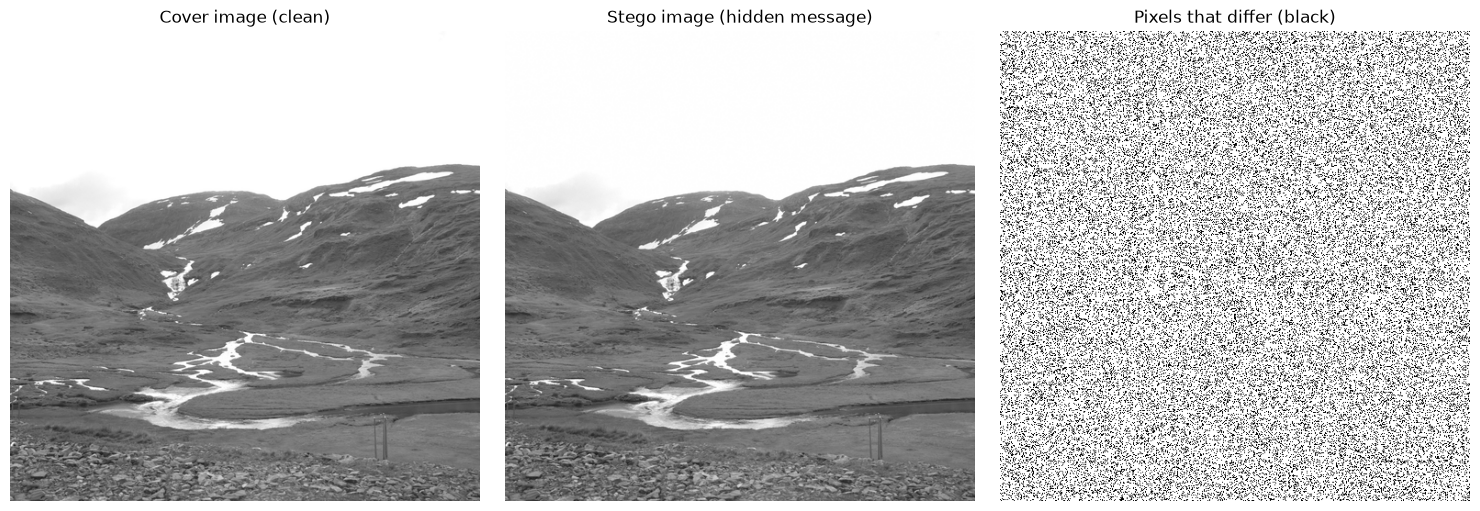

Image size: (512, 512)
Pixels changed by the hidden message: 53681 of 262144 (20.5%)
Largest change in any pixel value: 1


In [5]:
# Part B, Step 1: Load two images (cover and stego) from the BOSSbase sample collection
SAMPLES = "https://raw.githubusercontent.com/Sourish1997/steganalysis/master/"
COVER_URL = SAMPLES + "bossbase_sample/1.pgm"
STEGO_URL = SAMPLES + "bossbase_lsb_sample/1.pgm"

def load_grayscale_image(source):
    """Load an image from a URL or a local path as a 2D uint8 array (grayscale)."""
    if str(source).lower().startswith(("http://", "https://")):
        data = io.BytesIO(download_bytes(source))
    else:
        data = source
    return np.array(Image.open(data).convert("L"), dtype=np.uint8)

cover_image = load_grayscale_image(COVER_URL)
stego_image = load_grayscale_image(STEGO_URL)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cover_image, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Cover image (clean)")
axes[1].imshow(stego_image, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Stego image (hidden message)")
diff = (cover_image.astype(int) != stego_image.astype(int))
axes[2].imshow(diff, cmap="gray_r"); axes[2].set_title("Pixels that differ (black)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

print(f"Image size: {cover_image.shape}")
print(f"Pixels changed by the hidden message: {int(diff.sum())} of {diff.size} ({diff.mean():.1%})")
print(f"Largest change in any pixel value: {int(np.abs(cover_image.astype(int) - stego_image.astype(int)).max())}")

## Step 2: Extract the 41 Features from an Image

### Purpose
Turn an image into the same 41 numbers the model was trained on, then scale and compress them to 10 values.

### Input
- `image_array`: a grayscale image (512 x 512 pixels) as a 2D array.
- `scaler`, `pca`: the fitted objects from Part A, Step 2.

### Output
- `pca_features`: the 10-value vector the classifier expects.
- `raw_features`: the original 41 features (for display).

### The 41 features (these are the "Correlation Features")
| Group | Count | What it measures |
|---|---|---|
| Bit-plane correlation | 1 | How two bit planes of the image relate to each other |
| Bit-plane autocorrelation | 14 | How a bit plane relates to a shifted copy of itself, in 14 directions |
| Histogram features | 5 | Even vs odd pixel-value counts, and neighbouring histogram bins |
| Wavelet residual correlations | 21 | Fine texture and noise structure left after a wavelet de-noise (3 thresholds x 7 shifts) |

### Important consistency note
The pre-computed training CSV files were generated with exactly these definitions. In particular, the "bit plane 0" and "bit plane 1" used for the first 15 features are the **two most significant bit planes** (index 0 is the leftmost bit of the 8-bit pixel value). The histogram uses exact bins for each pixel value 0 to 255. **The extractor below must match the training data exactly, otherwise the model receives numbers on a different scale and its answer is meaningless.** (We checked this: on the sample images, this extractor reproduces the CSV rows to about 10 decimal places.)

In [6]:
# Part B, Step 2: Extract the 41 correlation features from a grayscale image
def get_bit_plane(img, plane_id):
    """Bit plane `plane_id` of an 8-bit image. plane 0 = most significant bit ... plane 7 = least significant bit."""
    return ((img >> (7 - plane_id)) & 1).astype(int)

def autocor(matrix, k, l):
    """Correlation between a matrix and a copy of itself shifted by (k, l)."""
    Xk = matrix[0:matrix.shape[0] - k, 0:matrix.shape[1] - l]
    Xl = matrix[k:matrix.shape[0], l:matrix.shape[1]]
    return pearsonr(Xk.flatten(), Xl.flatten())[0]

def hist_corr(hist, l):
    return pearsonr(hist[0:256 - l], hist[l:256])[0]

def wavelet_residual(img, threshold):
    """Image minus its wavelet-denoised version (small detail coefficients set to zero)."""
    LL, (LH, HL, HH) = pywt.dwt2(img, 'haar')
    LH, HL, HH = [np.where(np.abs(c) < threshold, 0, c) for c in (LH, HL, HH)]
    return img - pywt.idwt2((LL, (LH, HL, HH)), 'haar')

AUTOCOR_PAIRS = [[1, 0], [2, 0], [3, 0], [4, 0], [0, 1], [0, 2], [0, 3], [0, 4],
                 [1, 1], [2, 2], [3, 3], [4, 4], [1, 2], [2, 1]]
WAVELET_SHIFTS = [[0, 1], [1, 0], [1, 1], [0, 2], [2, 0], [1, 2], [2, 1]]
WAVELET_THRESHOLDS = [1.5, 2.0, 2.5]

def extract_41_features(image_array):
    """Return the 41 raw correlation features of a 2D uint8 grayscale image."""
    img = np.asarray(image_array, dtype=np.uint8)
    features = []

    # 1 feature: correlation between bit plane 0 and bit plane 1
    M1, M2 = get_bit_plane(img, 0), get_bit_plane(img, 1)
    features.append(pearsonr(M1.flatten(), M2.flatten())[0])

    # 14 features: autocorrelation of bit plane 0
    for k, l in AUTOCOR_PAIRS:
        features.append(autocor(M1, k, l))

    # 5 features: histogram-based (exact bins for pixel values 0..255)
    hist, _ = np.histogram(img.flatten(), bins=range(257), density=True)
    features.append(pearsonr(hist[::2], hist[1::2])[0])      # even bins vs odd bins
    for i in range(1, 5):
        features.append(hist_corr(hist, i))                  # bin shifted by 1..4

    # 21 features: autocorrelation of the wavelet residual
    for t in WAVELET_THRESHOLDS:
        residual = wavelet_residual(img.astype(float), t)
        for k, l in WAVELET_SHIFTS:
            features.append(autocor(residual, k, l))

    return np.array(features)

def extract_cf_features(image_array, scaler, pca):
    """Raw 41 features -> normalised -> PCA (10 values). Returns (pca_features, raw_features)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # silence "constant input" warnings for very dark/bright images
        raw_features = extract_41_features(image_array)
    if np.isnan(raw_features).any():
        raise ValueError("This image is too dark or too bright (a bit plane is constant), so some features "
                         "are undefined (NaN). It cannot be analysed.")
    pca_features = pca.transform(scaler.transform(raw_features.reshape(1, -1)))
    return pca_features, raw_features

# Try it on the cover image from Step 1
pca_f, raw_f = extract_cf_features(cover_image, scaler_model, pca_model)
print("The 41 raw features of the cover image (before PCA):")
print(np.round(raw_f, 4))
print("\nThe same image as 10 PCA features (what the classifier sees):")
print(np.round(pca_f, 3))

The 41 raw features of the cover image (before PCA):
[-3.173e-01  8.275e-01  7.606e-01  7.410e-01  7.214e-01  9.106e-01
  8.614e-01  8.352e-01  8.155e-01  8.183e-01  7.584e-01  7.327e-01
  7.123e-01  8.067e-01  7.594e-01  1.608e-01  2.146e-01  1.920e-01
  1.823e-01  1.762e-01 -2.844e-01 -1.147e-01 -5.360e-02 -9.000e-04
 -2.000e-04 -4.400e-03  3.900e-03 -2.544e-01 -1.585e-01 -4.410e-02
 -6.200e-03 -1.600e-03 -4.300e-03 -2.000e-04 -2.669e-01 -1.068e-01
 -5.970e-02 -1.520e-02 -6.700e-03 -4.300e-03  1.200e-03]

The same image as 10 PCA features (what the classifier sees):
[[ 0.467  3.496 -8.165 -8.066 -3.301  4.959 -1.496  0.16  -3.174 -0.355]]


## Step 3: Predict Whether the Images Contain a Hidden Message

### Purpose
Ask the trained model for a verdict on the cover image and the stego image from Step 1.

### Input
- The image, plus `scaler`, `pca` and `clf` from Part A.

### Output
- A label: `"Steg Image (LSB Matching Detected)"` or `"Cover Image (No LSB Matching)"`.
- The model's **probability** that the image is stego.

### How to read it
The probability is the fraction of the 100 trees that voted "stego". A probability of 0.95 is a confident call; 0.55 is close to a coin flip. A responsible report quotes the probability, not just the label.

> These sample images come from the same BOSSbase collection the model was trained on, so this is a **demonstration**, not a fair test. The fair test of accuracy is the held-out test result in Part A, Step 3.

In [7]:
# Part B, Step 3: Predict for one image (given as an array)
def predict_image(image_array, scaler, pca, clf):
    pca_features, _ = extract_cf_features(image_array, scaler, pca)
    prediction = clf.predict(pca_features)[0]
    prob_stego = clf.predict_proba(pca_features)[0, 1]
    label = "Steg Image (LSB Matching Detected)" if prediction == 1 else "Cover Image (No LSB Matching)"
    return label, prob_stego

for name, image in [("Cover image (truth: clean)", cover_image), ("Stego image (truth: hidden message)", stego_image)]:
    label, prob = predict_image(image, scaler_model, pca_model, clf)
    print(f"{name}")
    print(f"   Prediction: {label}   (probability of stego = {prob:.2f})\n")

Cover image (truth: clean)
   Prediction: Cover Image (No LSB Matching)   (probability of stego = 0.02)



Stego image (truth: hidden message)
   Prediction: Steg Image (LSB Matching Detected)   (probability of stego = 0.81)



## Step 4 (Optional): Test Your Own Image

Set `MY_IMAGE` to a **URL or a file path** of a 512 x 512 grayscale image (`.pgm` works best, because it is not compressed), then run the cell. Leave it empty to skip.

Notes:
- The image must be exactly 512 x 512 pixels (the features were designed for that size).
- **JPEG images are a poor fit.** JPEG compression rewrites the pixel values and destroys the least-significant-bit patterns this model relies on.
- Try other BOSSbase samples by changing the number, e.g. `.../bossbase_sample/7.pgm` and `.../bossbase_lsb_sample/7.pgm` (numbers 1 to 25 exist).

In [8]:
# Part B, Step 4 (optional): test your own image. Paste a URL or a file path between the quotes.
MY_IMAGE = ""   # example: "https://raw.githubusercontent.com/Sourish1997/steganalysis/master/bossbase_lsb_sample/7.pgm"

if MY_IMAGE.strip():
    try:
        my_array = load_grayscale_image(MY_IMAGE.strip())
        if my_array.shape != (512, 512):
            raise ValueError(f"The image must be 512x512 pixels, but this one is {my_array.shape[1]}x{my_array.shape[0]}.")
        label, prob = predict_image(my_array, scaler_model, pca_model, clf)
        plt.figure(figsize=(4, 4)); plt.imshow(my_array, cmap="gray", vmin=0, vmax=255); plt.axis("off"); plt.show()
        print(f"Prediction: {label}   (probability of stego = {prob:.2f})")
    except Exception as err:
        print("Could not analyse the image:", err)
else:
    print("MY_IMAGE is empty, so this step is skipped.")

MY_IMAGE is empty, so this step is skipped.


## Step 5: Scoreboard on Several Sample Pairs

Run the model on the first 8 cover / stego pairs and count how often it is right. Expect **mistakes**: the model is about 70 % accurate. Image pair **2** is an extreme case: the picture is so dark (no pixel above 121) that its most significant bit plane is all zeros, the correlations are undefined, and it cannot be analysed at all. A real examiner needs to know that limitation.

In [9]:
# Part B, Step 5: scoreboard over several sample pairs
rows, correct, total = [], 0, 0
for n in range(1, 9):
    for kind, folder, truth in (("cover", "bossbase_sample", 0), ("stego", "bossbase_lsb_sample", 1)):
        try:
            img = load_grayscale_image(f"{SAMPLES}{folder}/{n}.pgm")
            label, prob = predict_image(img, scaler_model, pca_model, clf)
            guess = 1 if label.startswith("Steg") else 0
            total += 1; correct += int(guess == truth)
            rows.append({"image": f"{n}.pgm", "truth": kind, "P(stego)": round(prob, 2),
                         "verdict": "stego" if guess else "cover", "correct": "yes" if guess == truth else "NO"})
        except ValueError as err:
            rows.append({"image": f"{n}.pgm", "truth": kind, "P(stego)": None, "verdict": "cannot analyse", "correct": "-"})
display_df = pd.DataFrame(rows)
print(display_df.to_string(index=False))
print(f"\nCorrect on {correct} of {total} analysable images ({correct/total:.0%}).")

image truth  P(stego)        verdict correct
1.pgm cover      0.02          cover     yes
1.pgm stego      0.81          stego     yes
2.pgm cover       NaN cannot analyse       -
2.pgm stego       NaN cannot analyse       -
3.pgm cover      0.24          cover     yes
3.pgm stego      0.60          stego     yes
4.pgm cover      0.57          stego      NO
4.pgm stego      0.71          stego     yes
5.pgm cover      0.71          stego      NO
5.pgm stego      0.77          stego     yes
6.pgm cover      0.62          stego      NO
6.pgm stego      0.63          stego     yes
7.pgm cover      0.69          stego      NO
7.pgm stego      0.79          stego     yes
8.pgm cover      0.59          stego      NO
8.pgm stego      0.62          stego     yes

Correct on 9 of 14 analysable images (64%).


## What Just Happened (Explanation of the Process)

1. **Data:** 20,000 rows of 41 pre-computed features, half from clean images and half from LSB-matching stego images.
2. **Preparation:** rows with undefined values were removed, the data was split into training and test sets, then normalised and compressed to 10 features using PCA fitted on the training set only.
3. **Model:** a Random Forest of 100 trees (maximum depth 10) learned to separate the two classes.
4. **Honest evaluation:** accuracy is reported on the unseen test set (about 70 %), not just on the training data (about 78 %).
5. **Prediction:** a new image goes through the *same* feature extraction, scaling and PCA, and the forest outputs a label with a probability.

### Limitations to state in any report
- **Moderate accuracy.** About 70 % on held-out data means roughly 3 mistakes in 10. One verdict is a lead, not proof.
- **Narrow scope.** The model only knows this kind of embedding (LSB matching) on 512 x 512 grayscale BOSSbase-style images. It says nothing about other hiding methods, colour images, or JPEG files.
- **Very dark or very bright images** can produce undefined features and cannot be analysed (see image pair 2 in Step 5).
- **Features must match training exactly.** Any difference in how the 41 features are computed silently ruins the predictions, so the extractor was verified against the training CSV.

### Discussion questions
1. Why is the confusion matrix more informative than a single accuracy number? Which mistake is worse for an investigator: a false alarm or a miss?
2. What would you do to raise the accuracy (more features, a different model, more data)?
3. What happens if the person hiding the message embeds fewer bits? Would you expect the model to do better or worse?